## Experiment 2: Pytorch vs Custom Fused GELU

**Objective:** Compare the performance and numerical equivalence of the standard PyTorch GELU activation with a custom fused GELU implementation. By running both functions under identical input conditions, we seek to evaluate any potential speedups and validate that the results remain within acceptable tolerance levels, ensuring the custom version is a reliable drop-in for standard model usage.

**Context**

GELU (Gaussian Error Linear Unit) is an activation function used in neural networks, particularly Transformers and models like GPT and BERT. Think of it as a smart filter that decides how much of a neuron's input should pass through to the next layer. Unlike ReLU, which completely blocks negative values and allows positive values through, GELU smoothly scales inputs based on their magnitude: large positive values pass through almost unchanged, large negative values approach zero, and values near zero are partially retained. This smooth behavior helps neural networks learn complex patterns.

Formula is provided below

![GELU Formula](https://substackcdn.com/image/fetch/$s_!rdOm!,f_auto,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2F953b81b7-2367-4edf-a872-6866ce53dcc8_956x384.png)

## Implementation

In [1]:
!nvidia-smi

Thu Oct 22 21:03:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install ninja

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 6.8 MB/s eta 0:00:00


In [6]:
# importing libraries
import torch
from torch.utils.cpp_extension import load_inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import __version__
import math

print("Library Versions:")
print("Pytorch: ", torch.__version__)
print("CUDA Available: ", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name: ", torch.cuda.get_device_name(0))
print("Numpy: ", np.__version__)
print("Pandas: ", pd.__version__)
print("Matplotlib: ", __version__)





Library Versions:
Pytorch:  2.11.0+cu130
CUDA Available:  True
GPU Name:  Tesla T4
Numpy:  2.1.3
Pandas:  2.2.3
Matplotlib:  3.10.0


In [9]:
cpp_code = """
#include <torch/extension.h>

torch::Tensor fused_gelu(torch::Tensor input);
"""

cuda_code = """
#include <torch/extension.h>
#include <cstdint>
#include <c10/cuda/CUDAException.h>

// This is the CUDA code for the fused GELU activation function.
__global__ void fused_gelu_cuda(const float* input, float* output, int size) {
    // Step 1: get the thread id from the block and grid
    int thread_id = blockIdx.x * blockDim.x + threadIdx.x;
    // Step 2: Check if the thread id is within the bounds of the input tensor
    if (thread_id < size){
        // Step 3: Apply the GELU activation function
        float x = input[thread_id];
        float gelu_value = 0.5f * (1.0f + erf(x / sqrt(2.0f)));
        output[thread_id] = gelu_value;
    }
}

// GELU Launcher
torch::Tensor fused_gelu(torch::Tensor input) {
    //Step 1: Implement Checks before launching kernels
    // 1.1 Check if input and output are on the same GPU
    TORCH_CHECK(input.device().is_cuda(), "Input must be on a GPU");
    // 1.2 Check if input is contiguous
    TORCH_CHECK(input.is_contiguous(), "Input must be contiguous");
    // 1.3 Check if input has float32 data type
    TORCH_CHECK(input.dtype() == torch::kFloat32, "Input must have float32 data type");
    // Step 2: Get the dimensions of the input tensor
    int size = input.numel();
    // Step 3: Create output tensor
    torch::Tensor output = torch::zeros_like(input);
    // Step 4: Launch the kernel
    //4.1 Configure grid and block dimensions
    int block_size = 256;
    int grid_size = (size + block_size - 1) / block_size;
    //4.2 Get pointers to the data
    const float* input_ptr = input.data_ptr<float>();
    float* output_ptr = output.data_ptr<float>();
    //4.3 Launch the kernel
    fused_gelu_cuda<<<grid_size, block_size>>>(input_ptr, output_ptr, size);
    //4.4 Check for errors
    C10_CUDA_KERNEL_LAUNCH_CHECK();
    //4.5 Return the output tensor
    return output;
}
"""

In [10]:
ext_name = "fused_gelu_v2"

module = load_inline(
    name=ext_name,
    cpp_sources=cpp_code,
    cuda_sources=cuda_code,
    functions=["fused_gelu"],
    extra_cuda_cflags=["-O3"],
    verbose=True
)

In [11]:
def pytorch_gelu(x):
    return 0.5 * (1.0 + torch.erf(x / math.sqrt(2.0)))

def custom_gelu(x):
    return module.fused_gelu(x)



In [12]:
torch.manual_seed(0)
N = 10_000_000
x = torch.randn(N, device="cuda", dtype=torch.float32)

y_pt = pytorch_gelu(x)
y_cu = custom_gelu(x)

err = (y_pt - y_cu).abs()
print("max abs", err.max().item())
print("mean abs", err.mean().item())
print("allclose: ", torch.allclose(y_pt, y_cu, rtol=1e-5, atol=1e-5))

max abs 1.1920928955078125e-07
mean abs 5.450701667797375e-09
allclose:  True


In [13]:
def bench(fn, x, iters=100, warmup=10):
    for _ in range(warmup):
        fn(x)
    torch.cuda.synchronize()

    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)
    start.record()
    for _ in range(iters):
        fn(x)
    end.record()
    torch.cuda.synchronize()
    return start.elapsed_time(end) / iters  # ms per call

print(f"pytorch  {bench(pytorch_gelu, x):.4f} ms")
print(f"custom   {bench(custom_gelu, x):.4f} ms")

pytorch  1.3472 ms
custom   0.5846 ms


In [14]:
from torch.profiler import profile, ProfilerActivity

def show_kernels(fn, x):
    for _ in range(5):
        fn(x)
    torch.cuda.synchronize()
    with profile(activities=[ProfilerActivity.CUDA]) as prof:
        fn(x)
        torch.cuda.synchronize()
    print(prof.key_averages().table(sort_by="self_cuda_time_total", row_limit=20))

show_kernels(pytorch_gelu, x)
show_kernels(custom_gelu, x)

-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
void at::native::vectorized_elementwise_kernel<4, at...         0.00%       0.000us         0.00%       0.000us       0.000us     335.388us        25.22%     335.388us     335.388us             1  
void at::native::vectorized_elementwise_kernel<4, at...         0.00%       0.000us         0.00%       0.000us       0.000us     335.324us        25.21%     335.324us     335.324us             1  
void at::

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


In [15]:
script = r'''
import argparse
import math
import torch
from torch.utils.cpp_extension import load_inline

parser = argparse.ArgumentParser()
parser.add_argument("--input-size", type=int, default=10_000_000)
parser.add_argument("--kernel", choices=["torch", "custom"], required=True)
args = parser.parse_args()

cpp_code = """
#include <torch/extension.h>
torch::Tensor fused_gelu(torch::Tensor input);
"""

cuda_code = """
#include <torch/extension.h>
#include <c10/cuda/CUDAException.h>

__global__ void fused_gelu_cuda(const float* input, float* output, int size) {
    int thread_id = blockIdx.x * blockDim.x + threadIdx.x;
    if (thread_id < size) {
        float x = input[thread_id];
        float gelu_value = 0.5f * (1.0f + erf(x / sqrt(2.0f)));
        output[thread_id] = gelu_value;
    }
}

torch::Tensor fused_gelu(torch::Tensor input) {
    TORCH_CHECK(input.device().is_cuda(), "Input must be on a GPU");
    TORCH_CHECK(input.is_contiguous(), "Input must be contiguous");
    TORCH_CHECK(input.dtype() == torch::kFloat32, "Input must have float32 data type");
    int size = input.numel();
    torch::Tensor output = torch::zeros_like(input);
    int block_size = 256;
    int grid_size = (size + block_size - 1) / block_size;
    fused_gelu_cuda<<<grid_size, block_size>>>(
        input.data_ptr<float>(), output.data_ptr<float>(), size);
    C10_CUDA_KERNEL_LAUNCH_CHECK();
    return output;
}
"""

def pytorch_gelu(x):
    return 0.5 * (1.0 + torch.erf(x / math.sqrt(2.0)))

if args.kernel == "custom":
    module = load_inline(
        name="fused_gelu_v2",
        cpp_sources=cpp_code,
        cuda_sources=cuda_code,
        functions=["fused_gelu"],
        extra_cuda_cflags=["-O3"],
        verbose=False,
    )
    fn = module.fused_gelu
else:
    fn = pytorch_gelu

x = torch.randn(args.input_size, device="cuda", dtype=torch.float32)
for _ in range(10):
    fn(x)
torch.cuda.synchronize()

torch.cuda.profiler.start()
fn(x)
torch.cuda.synchronize()
torch.cuda.profiler.stop()
'''

with open("gelu_profile.py", "w") as f:
    f.write(script)

In [16]:
!ncu --profile-from-start off \
    --metrics "dram__bytes_read,dram__bytes_write,l1tex__t_bytes_pipe_lsu_mem_global_op_ld,l1tex__t_bytes_pipe_lsu_mem_global_op_st" \
    --csv \
    python gelu_profile.py --kernel custom --input-size 10000000 > custom.csv

In [17]:
!ncu --profile-from-start off \
    --metrics "dram__bytes_read,dram__bytes_write,l1tex__t_bytes_pipe_lsu_mem_global_op_ld,l1tex__t_bytes_pipe_lsu_mem_global_op_st" \
    --csv \
    python gelu_profile.py --kernel torch --input-size 10000000 > torch.csv

,Global load,Global store,DRAM read,DRAM write,Global total,DRAM total,Global load MiB,Global store MiB,DRAM read MiB,DRAM write MiB,Global total MiB,DRAM total MiB,Bytes / element
Custom fused,40000000,80000000,44855488,86306464,120000000,131161952,38.15,76.29,42.78,82.31,114.44,125.09,12.0
PyTorch eager,160000000,160000000,181606144,172445760,320000000,354051904,152.59,152.59,173.19,164.46,305.18,337.65,32.0


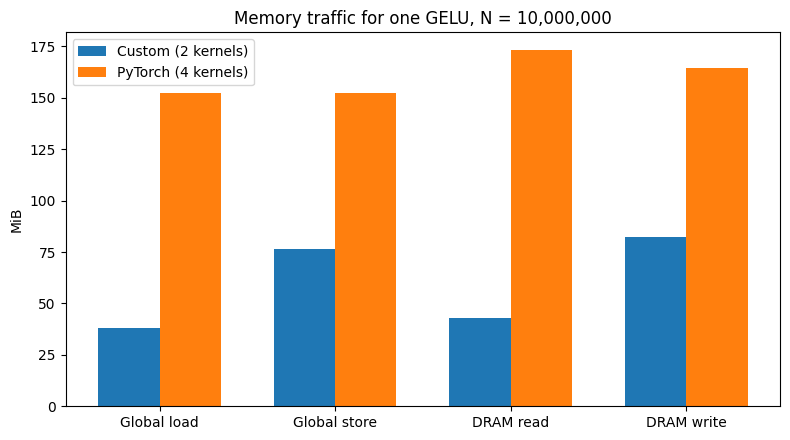

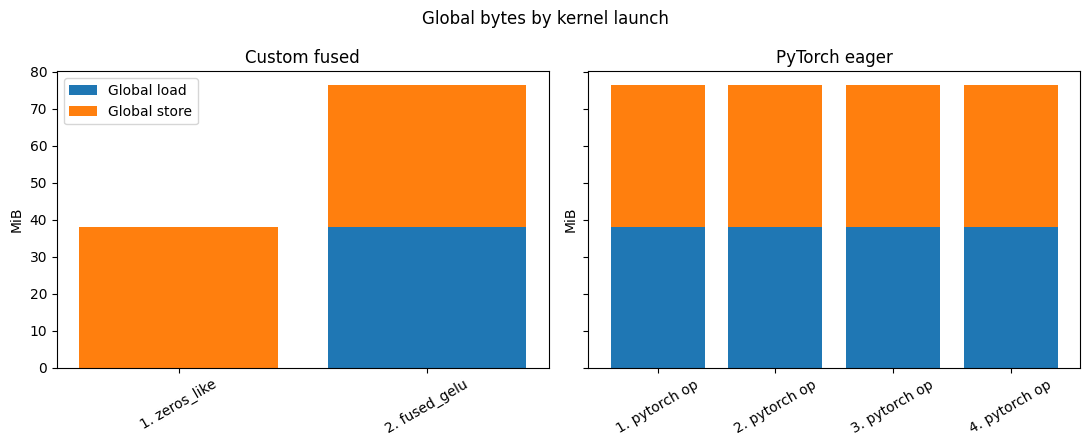

Kernel launches: custom 2, pytorch 4
Global bytes:    custom 120.0 MB, pytorch 320.0 MB
PyTorch / custom global-byte ratio: 2.67x
Useful traffic if the kernel only read x and wrote y: 80.0 MB
zeros_like adds one more full write: 120.0 MB
Four eager ops, each reading and writing the tensor: 320.0 MB


In [19]:

N = 10_000_000  # same --input-size passed to ncu

def load_ncu_csv(path):
    with open(path) as f:
        lines = f.readlines()
    header_idx = next(
        i for i, line in enumerate(lines)
        if '"ID"' in line and '"Kernel Name"' in line
    )
    df = pd.read_csv(path, skiprows=header_idx)
    df["Metric Value Numeric"] = pd.to_numeric(
        df["Metric Value"].astype(str).str.replace(",", "", regex=False),
        errors="coerce",
    )
    return df

def sum_rows(df):
    """One row per kernel, with the .sum metrics only."""
    sums = df[df["Metric Name"].str.endswith(".sum")].copy()
    rows = []
    for kernel_id, group in sums.groupby("ID", sort=True):
        name = str(group["Kernel Name"].iloc[0])
        row = {"ID": kernel_id, "Kernel": name}
        for metric, value in zip(group["Metric Name"], group["Metric Value Numeric"]):
            row[metric] = value
        rows.append(row)
    return pd.DataFrame(rows)

def short_name(name, idx):
    lower = name.lower()
    if "fused_gelu" in lower:
        label = "fused_gelu"
    elif "memset" in lower or "zero" in lower or "fill" in lower:
        label = "zeros_like"
    else:
        label = "pytorch op"
    return f"{idx}. {label}"

custom = sum_rows(load_ncu_csv("custom.csv"))
torch_df = sum_rows(load_ncu_csv("torch.csv"))

metrics = {
    "Global load": "l1tex__t_bytes_pipe_lsu_mem_global_op_ld.sum",
    "Global store": "l1tex__t_bytes_pipe_lsu_mem_global_op_st.sum",
    "DRAM read": "dram__bytes_read.sum",
    "DRAM write": "dram__bytes_write.sum",
}

def totals(df):
    return {label: df[col].sum() if col in df.columns else 0.0
            for label, col in metrics.items()}

custom_totals = totals(custom)
torch_totals = totals(torch_df)

summary = pd.DataFrame({
    "Custom fused": custom_totals,
    "PyTorch eager": torch_totals,
}).T
summary["Global total"] = summary["Global load"] + summary["Global store"]
summary["DRAM total"] = summary["DRAM read"] + summary["DRAM write"]
for col in summary.columns:
    summary[col + " MiB"] = summary[col] / (1024 ** 2)
summary["Bytes / element"] = summary["Global total"] / N

display(summary.round(2))

# --- Plot 1: total traffic ---
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["Global load", "Global store", "DRAM read", "DRAM write"]
x = range(len(labels))
width = 0.35
ax.bar([i - width / 2 for i in x],
       [custom_totals[k] / (1024 ** 2) for k in labels],
       width, label=f"Custom ({len(custom)} kernels)")
ax.bar([i + width / 2 for i in x],
       [torch_totals[k] / (1024 ** 2) for k in labels],
       width, label=f"PyTorch ({len(torch_df)} kernels)")
ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.set_ylabel("MiB")
ax.set_title(f"Memory traffic for one GELU, N = {N:,}")
ax.legend()
fig.tight_layout()
plt.show()

# --- Plot 2: each kernel's global load and store ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, df, title in (
    (axes[0], custom, "Custom fused"),
    (axes[1], torch_df, "PyTorch eager"),
):
    names = [short_name(n, i + 1) for i, n in enumerate(df["Kernel"])]
    load_col = metrics["Global load"]
    store_col = metrics["Global store"]
    load = df[load_col] / (1024 ** 2) if load_col in df else 0
    store = df[store_col] / (1024 ** 2) if store_col in df else 0
    ax.bar(names, load, label="Global load")
    ax.bar(names, store, bottom=load, label="Global store")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylabel("MiB")
axes[0].legend()
fig.suptitle("Global bytes by kernel launch")
fig.tight_layout()
plt.show()

global_custom = custom_totals["Global load"] + custom_totals["Global store"]
global_torch = torch_totals["Global load"] + torch_totals["Global store"]
print(f"Kernel launches: custom {len(custom)}, pytorch {len(torch_df)}")
print(f"Global bytes:    custom {global_custom/1e6:.1f} MB, pytorch {global_torch/1e6:.1f} MB")
print(f"PyTorch / custom global-byte ratio: {global_torch / global_custom:.2f}x")
print(f"Useful traffic if the kernel only read x and wrote y: {8 * N / 1e6:.1f} MB")
print(f"zeros_like adds one more full write: {(8 * N + 4 * N) / 1e6:.1f} MB")
print(f"Four eager ops, each reading and writing the tensor: {32 * N / 1e6:.1f} MB")

## Observations

1. The custom fused kernel achieved significantly lower global memory traffic compared to PyTorch's eager-mode implementation.
2. The custom fused approach used approximately 12 bytes/element, whereas the eager PyTorch implementation used around 32 bytes/element.
3. The number of kernel launches in the custom implementation is much smaller than in PyTorch eager mode, reflecting better kernel fusion.
4. Memory savings are evident in both global load/store and DRAM byte counts for the custom fused kernel.
5. The overhead in PyTorch is likely due to multiple intermediate tensors and redundant reads/writes that are avoided in the fused version.
6. These results show that custom kernel fusion is highly effective for reducing memory bandwidth usage and accelerating operations, particularly for large tensors.
7. The measured "useful" memory traffic (just read x, write y once) aligns much more closely to the custom fused result than to the PyTorch eager result, highlighting the inefficiency of non-fused approaches.
8. Using PyTorch's eager approach, with multiple operator calls, causes the memory traffic to grow linearly with the number of operations on the same tensor, while the fused kernel keeps it minimal.